# Flower Image Classification with CNNs and Transfer Learning

**Author:** Nazeer Idris · Applied Data Science & AI, Breda University of Applied Sciences (Year 1, 2024–25)

In this notebook I build an image classifier for five flower types (daisy, dandelion, rose, sunflower and tulip) using a dataset I collected and cleaned myself. I start from simple baselines and improve the model over four iterations:

1. **Dataset**: collecting, cleaning and splitting the images
2. **Baselines**: random guess, a multilayer perceptron and human-level performance
3. **Basic CNN** (iteration 1)
4. **CNN with data augmentation** (iteration 2)
5. **Transfer learning with MobileNetV2** (iteration 3)
6. **Model improvement with EfficientNetB0** (iteration 4), the final model at **95.4% test accuracy**
7. **Error analysis** of the final model's mistakes

> The dataset is not included in this repository. The notebook is saved with its outputs, so all results and plots can be read directly on GitHub.

In [1]:
import os
import logging
import warnings
import random
import cv2 
import imghdr
import imagehash 
import numpy as np
import splitfolders 

In [2]:
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv2D, Flatten, BatchNormalization, MaxPooling2D, Dropout, GlobalAveragePooling2D, SeparableConv2D, Activation
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.applications import EfficientNetB0
from sklearn.metrics import (
    confusion_matrix, classification_report, accuracy_score, 
    precision_score, recall_score, f1_score
)

In [4]:
# Set seeds
seed = 42
os.environ['PYTHONHASHSEED'] = str(seed)
np.random.seed(seed)
random.seed(seed)
tf.random.set_seed(seed)

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
logging.getLogger('tensorflow').setLevel(logging.ERROR)
warnings.filterwarnings('ignore')

## 1. Dataset

### Dataset Creation

##### **Dataset Collection Process**

I created a comprehensive flower image dataset by collecting images from three major image websites:

1. [Pexels](https://www.pexels.com/search/flowers/)
2. [Unsplash](https://unsplash.com/s/photos/flower) 
3. [Pixabay](https://pixabay.com/images/search/flowers/)

The dataset consists of 5 flower classes:
- Class: daisy - 874 images
- Class: dandelion - 938 images
- Class: rose - 876 images
- Class: sunflower - 872 images
- Class: tulip - 968 images

Total dataset size: 4528 images


### Dataset Cleaning

##### **Image Dataset Cleaning Process**

To prepare my image dataset for model training, I cleaned it in two main steps:

##### 1. Removed Invalid Image Files
- I checked each image file to see if its format was either **.jpg** or **.jpeg**.
- If an image had a different file format (like .png, .gif, etc.), it was **deleted**.
- I used the `cv2` and `imghdr` libraries to read and check each image.

##### 2. Removed Duplicate Images
- I used the `imagehash` library to calculate a **hash value** for each image.
- This hash represents the image content—so if two images looked the same, they had the same hash.
- If a duplicate was found (same hash as a previously seen image), it was **removed** to avoid redundancy.
- All images were first converted to **RGB** and saved in **JPEG** format to ensure consistency.

##### Results
- All non-jpg/jpeg files were removed.
- Many duplicate images across different classes were identified and deleted.
- Now the dataset is cleaner, smaller, and better prepared for training a machine learning model



In [5]:
# Folder with the raw images, one sub-folder per class (not included in this repository)
dir_path = os.path.join("..", "data", "flowers_raw")

In [6]:
# Check if images are jpg/jpeg, remove if not
image_exts = ["jpg", "jpeg"]

# Go through each class folder
for image_class in os.listdir(dir_path):
    for image in os.listdir(os.path.join(dir_path, image_class)):
        image_path = os.path.join(dir_path, image_class, image)
        try:
            img = cv2.imread(image_path)
            tip = imghdr.what(image_path)
            if tip not in image_exts:
                print(f"Image not in jpg/jpeg: {image_path}")
                os.remove(image_path)
        except Exception as e:
            print(f"Issue with image: {image_path}")


In [7]:
def clean_and_remove_duplicate_images(dataset_dir, valid_exts=("jpg", "jpeg", "png")):
    hashes = {}

    # Go through all images in dataset
    for root, _, files in os.walk(dataset_dir):
        for file in files:
            if file.lower().endswith(valid_exts):
                file_path = os.path.join(root, file)
                try:
                    
                    # Open and standardize image format
                    with Image.open(file_path) as img:
                        img = img.convert("RGB")
                        img.save(file_path, "JPEG")
                        # Get image hash to check duplicates
                        img_hash = imagehash.average_hash(img)

                    # Check if image is duplicate
                    if img_hash in hashes:
                        print(f"Duplicate found:\n  {file_path}\n  {hashes[img_hash]}\nRemoving: {file_path}")
                        os.remove(file_path)
                    else:
                        hashes[img_hash] = file_path
                except Exception as e:
                    print(f"Issue with the image {file_path}: {e}")


clean_and_remove_duplicate_images(dir_path)

### Final Dataset

### Getting the data
The images are not included in this repository. To re-run the notebook, put the cleaned images in one folder per class under `data/flowers_raw/` (for example `data/flowers_raw/daisy/`). The split in the next section writes `train/`, `val/` and `test/` folders to `data/flowers/`.

### Load and Split

**In this step, I prepared my cleaned flower image dataset for machine learning by doing the following:**

1. **Checked Dataset Structure:**
I printed the number of images in each flower class to make sure the dataset is correctly organized into separate folders (one for each class).

2. **Loaded the Dataset in TensorFlow:**
I used image_dataset_from_directory to load all the images as a TensorFlow dataset to show some examples of the classes:
- Image size: 256x256
- Batch size: 32
- Shuffling enabled

This helped me preview the dataset and make sure everything was loading correctly.

3. **Displayed Sample Images**
I displayed 6 random images with their labels using matplotlib to visually confirm that the images matched their expected classes.

4. **Split the Dataset into Train, Validation, and Test Sets**
I used the splitfolders Python library to split the dataset into:
- 70% Training
- 20% Validation
- 10% Test

Each split is saved in a separate folder, ensuring there is no overlap between the sets. This prevents data leakage and helps build a reliable model.

Now the dataset is ready for training and evaluation.

In [8]:
# Check if dataset is structured correctly
for class_name in os.listdir(dir_path):
    class_path = os.path.join(dir_path, class_name)
    if os.path.isdir(class_path):
        print(f"Class: {class_name} - {len(os.listdir(class_path))} images")


Class: daisy - 874 images
Class: dandelion - 938 images
Class: rose - 876 images
Class: sunflower - 872 images
Class: tulip - 968 images


In [9]:
# Load images as a dataset with 256x256 resolution to show some samples
data = tf.keras.utils.image_dataset_from_directory(
    dir_path,
    image_size=(256, 256),
    batch_size=32, 
    shuffle=True
)

# Create an iterator for iterating through batches easily
data_iterator = data.as_numpy_iterator()

Found 4528 files belonging to 5 classes.


Sample labels: [3 2 1 1 3 1 1 0 1 0 2 3 0 0 0 1 4 1 0 4 2 2 0 4 3 3 0 3 2 3 0 4]


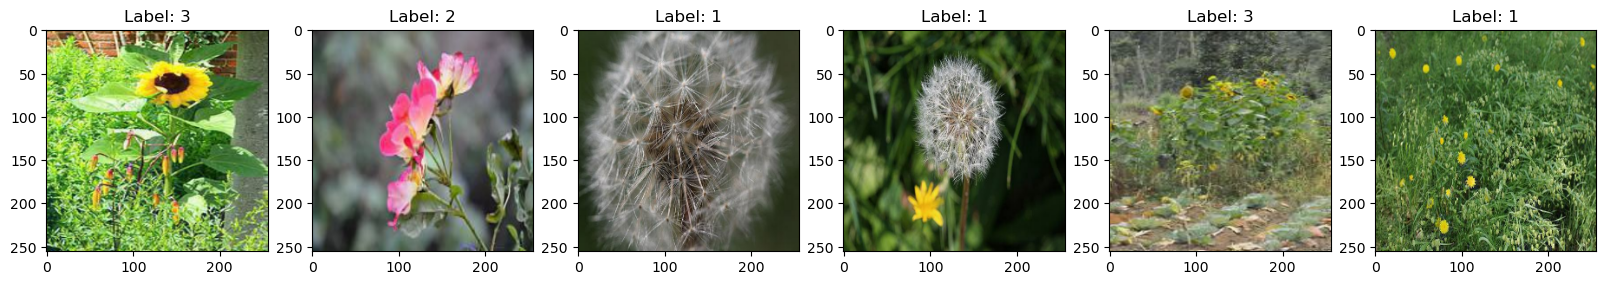

In [ ]:
# Get a batch of sample images and their labels
batch = data_iterator.next()
print("Sample labels:", batch[1])

# Display 6 sample images with their labels
fig, ax = plt.subplots(ncols=6, figsize=(20, 20))
for idx, img in enumerate(batch[0][:6]):
    ax[idx].imshow(img.astype(int))
    ax[idx].set_title(f"Label: {batch[1][idx]}")
plt.show()


In [11]:
# Splitting the dataset into training, validation, and test sets
input_folder = dir_path
output_folder = os.path.join("..", "data", "flowers")

# Using a 70/20/10 split for train/val/test respectively
splitfolders.ratio(input_folder, output=output_folder,
                   seed=42, ratio=(0.7, 0.2, 0.1),
                   group_prefix=None)

In [12]:
# Define paths for later use
train_path = os.path.join(output_folder, "train")
val_path = os.path.join(output_folder, "val")
test_path = os.path.join(output_folder, "test")

## 2. Baselines

### Random Guess Accuracy

##### **Random Guess Accuracy (Baseline)**

To understand how well a random model would perform, I calculated the expected accuracy if the model made predictions **completely by chance**.


#####  Case 1: Equal Chance for Each Class
There are **5 flower classes**: daisy, dandelion, rose, sunflower, and tulip.

If the model guesses randomly and each class has the same number of images, the accuracy would be:

**Accuracy = 100% / 5 = 20%**


#####  Case 2: Adjusted for Class Imbalance

My dataset has slightly different numbers of images in each class:

- Daisy: 880 images  
- Dandelion: 938 images  
- Rose: 876 images  
- Sunflower: 873 images  
- Tulip: 968 images  
- **Total: 4535 images**

###### Step 1: Calculate Proportions  
We find the proportion of each class in the dataset:

- Daisy: 880 / 4535 ≈ 0.1941  
- Dandelion: 938 / 4535 ≈ 0.2068  
- Rose: 876 / 4535 ≈ 0.1932  
- Sunflower: 873 / 4535 ≈ 0.1925  
- Tulip: 968 / 4535 ≈ 0.2134  

###### Step 2: Square the Proportions and Add Them

- (0.1941² ≈ 0.0377)  
- (0.2068² ≈ 0.0428)  
- (0.1932² ≈ 0.0373)  
- (0.1925² ≈ 0.0371)  
- (0.2134² ≈ 0.0455)  

**Sum ≈ 0.2004**

###### Step 3: Multiply by 100 to Get Accuracy  
**Accuracy ≈ 0.2004 × 100 = 20.04%**


##### Final Result

- **Random Guess (Balanced Classes): 20%**  
- **Random Guess (Adjusted for Class Imbalance): ~20.04%**

This gives us a **baseline**. Any model we build should aim to perform **better than 20%**, otherwise it's just guessing


### Basic Multilayer Perceptron Accuracy

##### I: Preprocessing
- Loaded training, validation, and test image datasets.
- Rescaled images to [0, 1] for better training.
- Used caching, shuffling, and prefetching for performance.

##### II: MLP Architecture
- Built a simple MLP model with two hidden layers.
- Used ReLU activation and softmax for classification.
- Compiled with Adam optimizer and categorical crossentropy.

##### III: MLP Training
- Trained the model with 3 learning rates: 0.01, 0.001, 0.0001.
- Used early stopping to prevent overfitting.
- Stored training history for each learning rate.

##### IV: Evaluation
- Plotted accuracy and loss curves to compare learning rates.
- Evaluated the final model on the test set.

#### I: Preprocessing

In [13]:
# Define image size and batch size for our training configuration
IMAGE_SIZE = (180, 180) 
BATCH_SIZE = 64    

In [14]:
# Load training data
train_data = tf.keras.preprocessing.image_dataset_from_directory(
    train_path,
    label_mode='categorical',
    batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE,
    shuffle=True
)

Found 3167 files belonging to 5 classes.


In [15]:
# Load validation data
val_data = tf.keras.preprocessing.image_dataset_from_directory(
    val_path,        
    label_mode='categorical',
    batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE,
    shuffle=True     
)

Found 903 files belonging to 5 classes.


In [16]:
# Load test data
test_data = tf.keras.preprocessing.image_dataset_from_directory(
    test_path,
    label_mode='categorical',
    batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE,
    shuffle=True
)

Found 458 files belonging to 5 classes.


In [17]:
# Rescale pixel values to [0, 1] for all datasets to help our model train better
normalization_layer = tf.keras.layers.Rescaling(1./255)
train_data = train_data.map(lambda x, y: (normalization_layer(x), y))
val_data = val_data.map(lambda x, y: (normalization_layer(x), y))
test_data = test_data.map(lambda x, y: (normalization_layer(x), y))

In [18]:
# Prepare training and validation datasets for efficient performance with caching, shuffling, and prefetching
AUTOTUNE = tf.data.AUTOTUNE
train_data = train_data.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_data = val_data.cache().prefetch(buffer_size=AUTOTUNE)

#### II: MLP Architecture 

In [19]:
def create_model(learning_rate):
    # Build a simple MLP
    model = tf.keras.Sequential([
        tf.keras.layers.Flatten(input_shape=(*IMAGE_SIZE, 3)),
        tf.keras.layers.Dense(128, activation='relu'),
        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.Dense(5, activation='softmax')
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model


#### III: MLP Training

In [20]:
# Early stopping will halt training if the validation loss doesn't improve for 2 epochs.
early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)

histories = {}

# Trying out a few learning rates
learning_rates = [0.01, 0.001, 0.0001]

for lr in learning_rates:
    print("\nTraining with learning rate:", lr)
    model = create_model(learning_rate=lr)
    history = model.fit(
        train_data,
        validation_data=val_data,
        epochs=50,
        callbacks=[early_stop],
        verbose=1
    )
    histories[lr] = history
 


Training with learning rate: 0.01
Epoch 1/50
50/50 [==============================] - 8s 75ms/step - loss: 97.7488 - accuracy: 0.2289 - val_loss: 7.0555 - val_accuracy: 0.2901
Epoch 2/50
50/50 [==============================] - 2s 48ms/step - loss: 2.7968 - accuracy: 0.3249 - val_loss: 1.6932 - val_accuracy: 0.3289
Epoch 3/50
50/50 [==============================] - 2s 44ms/step - loss: 2.3475 - accuracy: 0.2637 - val_loss: 1.5499 - val_accuracy: 0.2946
Epoch 4/50
50/50 [==============================] - 2s 43ms/step - loss: 1.5142 - accuracy: 0.3214 - val_loss: 1.4730 - val_accuracy: 0.3499
Epoch 5/50
50/50 [==============================] - 2s 45ms/step - loss: 1.4731 - accuracy: 0.3375 - val_loss: 1.4974 - val_accuracy: 0.3355
Epoch 6/50
50/50 [==============================] - 2s 45ms/step - loss: 1.4466 - accuracy: 0.3508 - val_loss: 1.4728 - val_accuracy: 0.3367
Epoch 7/50
50/50 [==============================] - 2s 42ms/step - loss: 1.4528 - accuracy: 0.3489 - val_loss: 1.5674 

#### IV: MLP Evaluation

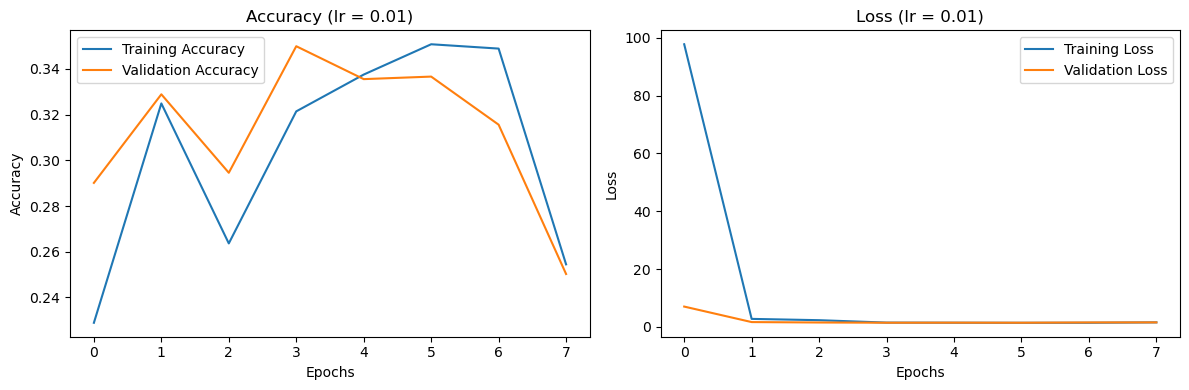

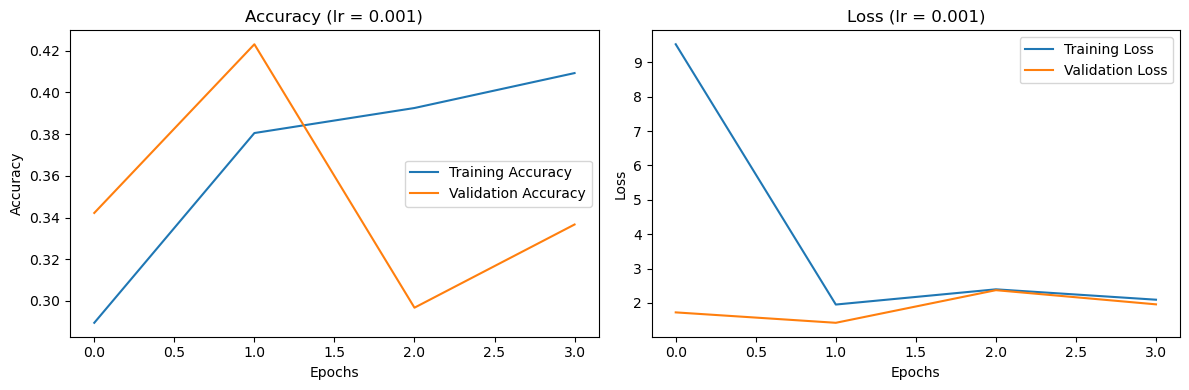

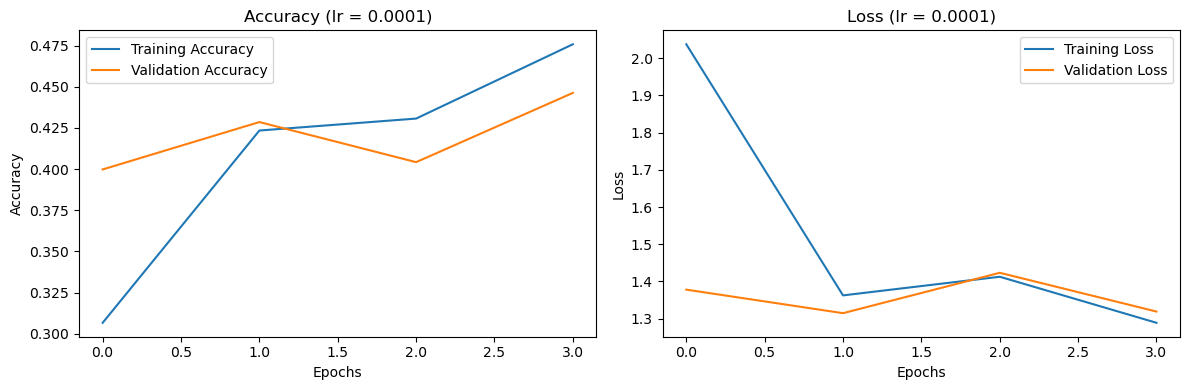

In [21]:
for lr, history in histories.items():
    plt.figure(figsize=(12, 4))

    # Accuracy subplot
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title(f'Accuracy (lr = {lr})')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    # Loss subplot
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title(f'Loss (lr = {lr})')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    plt.tight_layout()
    plt.show()

In [22]:
# Evaluate the model using the test dataset
test_loss, test_acc = model.evaluate(test_data)
print("Test accuracy:", test_acc)

8/8 [==============================] - 1s 16ms/step - loss: 1.2676 - accuracy: 0.4432
Test accuracy: 0.4432314336299896


**The accuracy that I got for the MLP is ≈ 45%**

### Human-Level Performance Accuracy

#####  **Human-Level Performance Baseline**

To estimate how well a human can perform on the flower classification task, I created a survey using Microsoft Forms. The form contained **50 images**, and each question asked:

> “What is the class of this image?”

The options were the five flower classes in my dataset:
- Daisy
- Dandelion
- Rose
- Sunflower
- Tulip

---

#####  Survey Participation
I shared the form with 3 of my peers and collected their responses. The survey results were:

- **Total Participants:** 3  
- **Average Score:** 46 out of 50  
- **Average Time Spent:** 3 minutes and 37 seconds


---

#####  Human-Level Accuracy Calculation

**46 correct answers out of 50**  
So,

**46 ÷ 50 = 0.92 → 92% accuracy**

---

#####  Final Result

- **Human-Level Performance Baseline:** **92% Accuracy**

This score represents a strong benchmark for comparing my model's performance. It gives an idea of what an expert (or well-informed person) might achieve on this classification task.


## 3. Basic CNN (Iteration 1)

### Preprocessing

In this step, I prepared the image data for training a CNN model. Here's what I did:

1. **Set image and batch size**  
   I chosed an image size of 128x128 pixels and a batch size of 64 images per batch.

2. **Load datasets**  
   We loaded the images from three folders: `train`, `validation`, and `test`. The images were automatically labeled based on their folder names (5 classes total), and the labels were encoded as one-hot vectors using `label_mode='categorical'`.

3. **Shuffle the data**  
   Shuffling was applied when loading the datasets to make sure the model doesn’t learn any order or pattern from the data sequence.

4. **Normalize pixel values**  
   We rescaled the pixel values from the range [0, 255] to [0, 1] using a `Rescaling` layer. This helps the model train more effectively by standardizing the input data.

5. **Optimize data loading**  
   We used `.cache()`, `.shuffle()`, and `.prefetch()` to speed up training:
   - `cache()` stores the dataset in memory after the first epoch to avoid reading from disk again.
   - `shuffle(1000)` randomizes the training data to prevent the model from learning any unwanted patterns.
   - `prefetch(AUTOTUNE)` allows the model to prepare the next batch of data while the current one is being processed, making training faster and smoother.


In [23]:
# Define image size and batch size for our training configuration
IMAGE_SIZE = (128, 128)
BATCH_SIZE = 64  

In [24]:
# Load training data
train_data = tf.keras.preprocessing.image_dataset_from_directory(
    train_path,
    label_mode='categorical',
    batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE,
    shuffle=True
)

Found 3167 files belonging to 5 classes.


In [25]:
# Load validation data
val_data = tf.keras.preprocessing.image_dataset_from_directory(
    val_path,
    label_mode='categorical',
    batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE,
    shuffle=True
)

Found 903 files belonging to 5 classes.


In [26]:
# Load test data
test_data = tf.keras.preprocessing.image_dataset_from_directory(
    test_path,
    label_mode='categorical',
    batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE,
    shuffle=True
)

Found 458 files belonging to 5 classes.


In [27]:
# Rescale pixel values to [0, 1] for all datasets to help our model train better
normalization_layer = tf.keras.layers.Rescaling(1./255)
train_data = train_data.map(lambda x, y: (normalization_layer(x), y))
val_data = val_data.map(lambda x, y: (normalization_layer(x), y))
test_data = test_data.map(lambda x, y: (normalization_layer(x), y))

In [28]:
# Prepare training and validation datasets for efficient performance with caching, shuffling, and prefetching
AUTOTUNE = tf.data.AUTOTUNE
train_data = train_data.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_data = val_data.cache().prefetch(buffer_size=AUTOTUNE)

### CNN Architecture

I built a simple CNN model to classify images into 5 categories. Here's the structure and reasoning:

1. **Conv + MaxPooling Layers**  
   I used four convolutional layers with increasing filters (32 to 128) and ReLU activation, each followed by a max pooling layer to reduce spatial dimensions and focus on key features.

2. **Flatten + Dense Layers**  
   After flattening the feature maps, I added a dense layer with 512 neurons and ReLU, along with a dropout layer (0.5) to reduce overfitting.

3. **Output Layer**  
   The final layer uses `softmax` to output probabilities for 5 classes.

4. **Compilation**  
   I compiled the model with the Adam optimizer, categorical cross-entropy loss, and accuracy as the evaluation metric.

5. **Model Summary**  
   I printed the model summary to review the architecture and parameter count.

In [29]:
# A simple CNN for image classification
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(*IMAGE_SIZE, 3)),
    MaxPooling2D((2, 2)),
    
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    
    Flatten(),
    Dense(512, activation='relu'),
    Dropout(0.5),
    Dense(5, activation='softmax')
])

# Compiling the model with Adam optimizer and cross entropy loss, then printing the summary for a quick sanity check
model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()



Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 126, 126, 32)      896       
                                                                 
 max_pooling2d (MaxPooling2  (None, 63, 63, 32)        0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 61, 61, 64)        18496     
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 30, 30, 64)        0         
 g2D)                                                            
                                                                 
 conv2d_2 (Conv2D)           (None, 28, 28, 128)       73856     
                                                                 
 max_pooling2d_2 (MaxPoolin  (None, 14, 14, 128)      

### CNN Training

To train my CNN model, I followed this strategy:

1. **Early Stopping**  
   I used early stopping to avoid overfitting. Training stops automatically if the validation loss doesn't improve for 5 epochs, and it restores the best model weights.

2. **Training Setup**  
   I trained the model for up to 50 epochs using both the training and validation datasets. The goal was to give the model enough time to learn while preventing it from overfitting.

This setup helped me find a good balance between training time and model performance.

In [30]:
# Early stopping to prevent overfitting: stop training when the validation loss doesn't improve for 5 epochs,
early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

# Train the model for up to 50 epochs using the training and validation datasets.
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=50,
    callbacks=[early_stop],
    verbose=1
)

model.save('flower_classifier.h5')  # backup
model.save('flower_classifier', save_format='tf')  # Primary format

Epoch 1/50
50/50 [==============================] - 16s 274ms/step - loss: 1.5089 - accuracy: 0.3183 - val_loss: 1.2284 - val_accuracy: 0.5161
Epoch 2/50
50/50 [==============================] - 13s 253ms/step - loss: 1.2165 - accuracy: 0.4904 - val_loss: 1.1478 - val_accuracy: 0.5360
Epoch 3/50
50/50 [==============================] - 12s 248ms/step - loss: 1.1221 - accuracy: 0.5526 - val_loss: 0.9733 - val_accuracy: 0.6135
Epoch 4/50
50/50 [==============================] - 12s 248ms/step - loss: 0.9744 - accuracy: 0.6249 - val_loss: 0.8827 - val_accuracy: 0.6578
Epoch 5/50
50/50 [==============================] - 13s 250ms/step - loss: 0.8880 - accuracy: 0.6577 - val_loss: 0.8987 - val_accuracy: 0.6501
Epoch 6/50
50/50 [==============================] - 12s 244ms/step - loss: 0.8224 - accuracy: 0.6890 - val_loss: 0.8241 - val_accuracy: 0.6700
Epoch 7/50
50/50 [==============================] - 12s 249ms/step - loss: 0.7397 - accuracy: 0.7240 - val_loss: 0.8130 - val_accuracy: 0.6833

### Model Evaluation

To evaluate my CNN model, I followed these steps:

1. **Learning Curves**  
   I plotted the training and validation accuracy and loss over the epochs. This helped me monitor the model’s learning progress and check for signs of overfitting or underfitting.

2. **Performance Metrics**  
   I evaluated the model on the test dataset by calculating accuracy, precision, recall, and F1 score. These metrics gave me a general sense of how well the model was performing across all classes.

3. **Confusion Matrix**  
   I generated a confusion matrix to visualize how well the model predicted each class. This helped identify which classes were more likely to be confused with each other.

This evaluation gave me a well-rounded understanding of the model's strengths and areas for improvement.

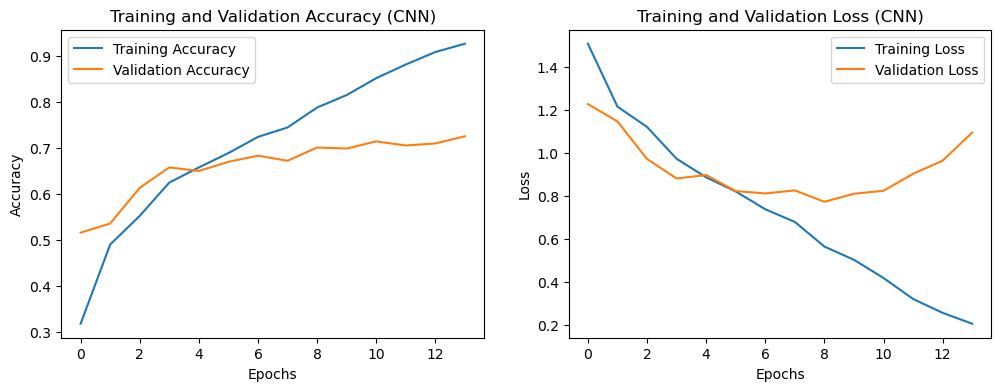

In [31]:
# Plot learning curves
plt.figure(figsize=(12, 4))

# Plot Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy (CNN)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss (CNN)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [32]:
# Collect predictions and true labels
y_true = []
y_pred = []

for images, labels in test_data:
    predictions = model.predict(images)  
    y_pred.extend(np.argmax(predictions, axis=1))  
    y_true.extend(np.argmax(labels.numpy(), axis=1)) 

y_true = np.array(y_true)
y_pred = np.array(y_pred)


1/1 [==============================] - 0s 92ms/step


In [33]:
# Calculate performance metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average='weighted')
recall = recall_score(y_true, y_pred, average='weighted')
f1 = f1_score(y_true, y_pred, average='weighted')

print("Accuracy: {:.2f}%".format(accuracy * 100))
print("Precision: {:.2f}".format(precision))
print("Recall: {:.2f}".format(recall))
print("F1 Score: {:.2f}".format(f1))

Accuracy: 73.36%
Precision: 0.74
Recall: 0.73
F1 Score: 0.73


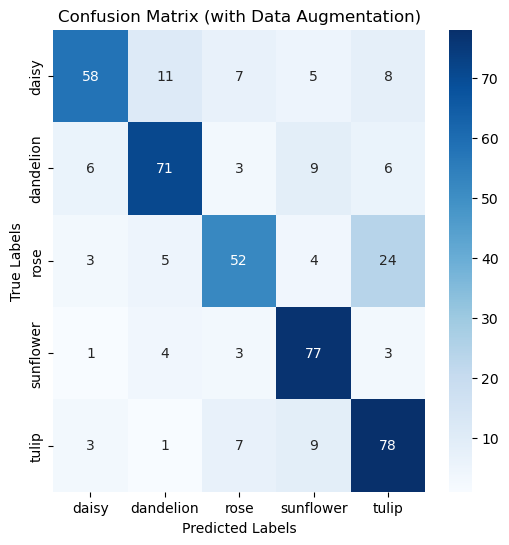

In [34]:
# Compute and plot the confusion matrix
cm = confusion_matrix(y_true, y_pred)
class_names = ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']  # Update if your classes are different

plt.figure(figsize=(6, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.title("Confusion Matrix (with Data Augmentation)")
plt.show()

**In this basic CNN iteration I got an accuracy of ≈ 73% which is much better than the previous baseline MLP model ≈ 45%**

## 4. Data Augmentation (Iteration 2)

### Preprocessing

In this iteration, we applied several data augmentation and preprocessing techniques to improve the model's ability to generalize. Here's a breakdown of the steps:

1. **Data Augmentation Pipeline**  
   We used a combination of transformations to make the training images more varied:
   - Random horizontal flips
   - Random rotations (up to 15%)
   - Random zooming (up to 20%)
   - Brightness adjustments
   - Contrast adjustments
   - Random cropping to 120x120
   - Resizing back to 128x128
   - Adding Gaussian noise

2. **Image Normalization**  
   After augmentation, all pixel values were scaled to the range `[0, 1]` using `Rescaling(1./255)`.

3. **Dataset Preparation**  
   - **Training Data**: Augmentation + normalization were applied.
   - **Validation & Test Data**: Only normalization was applied (no augmentation).

4. **Performance Optimization**  
   - **Caching**: Stores processed data in memory for faster access.
   - **Shuffling**: Ensures training data is randomly ordered.
   - **Prefetching**: Loads the next batch while the current one is training, improving efficiency.

In [35]:
# This pipeline applies a mix of random flips, rotations, zooms, brightness, contrast tweaks, crops, resizing, and a dash of noise.
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.15),
    tf.keras.layers.RandomZoom(0.2),
    tf.keras.layers.RandomBrightness(factor=0.2),
    tf.keras.layers.RandomContrast(factor=0.2),
    tf.keras.layers.RandomCrop(120, 120),
    tf.keras.layers.Resizing(128, 128),
    tf.keras.layers.GaussianNoise(stddev=0.1)
])

In [36]:
# Define image size and batch size for our training configuration
IMAGE_SIZE = (128, 128)
BATCH_SIZE = 64  

In [37]:
# Load training data
train_data = tf.keras.preprocessing.image_dataset_from_directory(
    train_path,
    label_mode='categorical',
    batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE,
    shuffle=True
)

Found 3167 files belonging to 5 classes.


In [38]:
# Load validation data
val_data = tf.keras.preprocessing.image_dataset_from_directory(
    val_path,
    label_mode='categorical',
    batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE,
    shuffle=True
)

Found 903 files belonging to 5 classes.


In [39]:
# Load test data
test_data = tf.keras.preprocessing.image_dataset_from_directory(
    test_path,
    label_mode='categorical',
    batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE,
    shuffle=True
)

Found 458 files belonging to 5 classes.


In [40]:
normalization_layer = tf.keras.layers.Rescaling(1./255)

def augment_and_normalize(images, labels):
    # Augment images then normalize them
    augmented = data_augmentation(images)
    normalized = normalization_layer(augmented)
    return normalized, labels

def normalize_only(images, labels):
    return normalization_layer(images), labels


In [41]:
# Apply augmentation to training data only
train_data_aug = train_data.map(augment_and_normalize)
val_data = val_data.map(normalize_only)
test_data = test_data.map(normalize_only)


In [42]:
# Prepare training and validation datasets for efficient performance with caching, shuffling, and prefetching
AUTOTUNE = tf.data.AUTOTUNE
train_data_aug = train_data_aug.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_data = val_data.cache().prefetch(buffer_size=AUTOTUNE)
test_data = test_data.prefetch(buffer_size=AUTOTUNE)


### CNN Architecture

##### Strategy:
- **Start Simple, Add Depth**: We started with a basic Conv2D layer and gradually increased the number of filters to learn more complex features at deeper layers.
- **MaxPooling**: Used after each convolutional layer to reduce spatial dimensions and keep the most important information.
- **Flatten & Dense Layers**: After feature extraction, we flattened the output and passed it through a dense layer with 512 units to make predictions.
- **Dropout**: Added dropout (50%) to reduce overfitting.
- **Output Layer**: Used a softmax activation to output probabilities for 5 classes.

##### Model Summary:
- 4 Convolutional layers with increasing filters: 32 → 64 → 128 → 128
- MaxPooling after each Conv2D
- 1 Dense hidden layer (512 units)
- 1 Dropout layer (rate: 0.5)
- Final Dense output layer with softmax for multi-class classification

This architecture balances simplicity and performance, making it suitable for our image dataset.

In [43]:
# Define a simple CNN model
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(*IMAGE_SIZE, 3)),
    MaxPooling2D((2, 2)),
    
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    
    Flatten(),
    Dense(512, activation='relu'),
    Dropout(0.5),
    Dense(5, activation='softmax')
])

model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential_5"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_4 (Conv2D)           (None, 126, 126, 32)      896       
                                                                 
 max_pooling2d_4 (MaxPoolin  (None, 63, 63, 32)        0         
 g2D)                                                            
                                                                 
 conv2d_5 (Conv2D)           (None, 61, 61, 64)        18496     
                                                                 
 max_pooling2d_5 (MaxPoolin  (None, 30, 30, 64)        0         
 g2D)                                                            
                                                                 
 conv2d_6 (Conv2D)           (None, 28, 28, 128)       73856     
                                                                 
 max_pooling2d_6 (MaxPoolin  (None, 14, 14, 128)      

### CNN Training

##### Training Strategy:

To train the CNN model effectively, we used the following approach:

1. **Augmented Data**:  
   We trained the model using the augmented training data created in the preprocessing step. This helps the model learn more robust features and generalize better.

2. **Validation Data**:  
   Used clean (non-augmented) validation data to monitor the model's performance on unseen data after each epoch.

3. **Early Stopping**:  
   Implemented `EarlyStopping` to avoid overfitting. Training stops if the validation loss doesn't improve for 5 consecutive epochs. The model automatically restores the weights from the best epoch.

4. **Training Configuration**:
   - Optimizer: **Adam**
   - Loss Function: **Categorical Crossentropy**
   - Metric: **Accuracy**
   - Max Epochs: **50**
   - Batch Size: **64**

In [44]:
# Early stopping: stop training if validation loss doesn't improve for 5 epochs.
early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

# Train model using augmented training data.
history = model.fit(
    train_data_aug,
    validation_data=val_data,
    epochs=50,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/50
50/50 [==============================] - 20s 254ms/step - loss: 1.4668 - accuracy: 0.3252 - val_loss: 1.3186 - val_accuracy: 0.4131
Epoch 2/50
50/50 [==============================] - 11s 228ms/step - loss: 1.3203 - accuracy: 0.4272 - val_loss: 1.1849 - val_accuracy: 0.4662
Epoch 3/50
50/50 [==============================] - 11s 226ms/step - loss: 1.2346 - accuracy: 0.4743 - val_loss: 1.1322 - val_accuracy: 0.5249
Epoch 4/50
50/50 [==============================] - 11s 226ms/step - loss: 1.1147 - accuracy: 0.5592 - val_loss: 0.9526 - val_accuracy: 0.6058
Epoch 5/50
50/50 [==============================] - 12s 233ms/step - loss: 1.0281 - accuracy: 0.6009 - val_loss: 0.9667 - val_accuracy: 0.6235
Epoch 6/50
50/50 [==============================] - 11s 216ms/step - loss: 0.9901 - accuracy: 0.6160 - val_loss: 0.9779 - val_accuracy: 0.6091
Epoch 7/50
50/50 [==============================] - 11s 227ms/step - loss: 0.9267 - accuracy: 0.6391 - val_loss: 0.9666 - val_accuracy: 0.6279

### Model Evaluation

To evaluate our CNN model, we followed a multi-step approach:

1. **Learning Curves**  
   - Plotted training and validation accuracy and loss over each epoch.
   - These graphs help identify if the model is learning well or overfitting.

2. **Test Set Evaluation**  
   - Used the test dataset (not seen during training or validation) to measure how well the model generalizes.
   - Gathered predictions and compared them to the true labels.

3. **Performance Metrics**  
   We calculated the following metrics to assess the model's performance:
   - **Accuracy**
   - **Precision**
   - **Recall**
   - **F1 Score**

   These metrics give a balanced view of how well the model is performing overall and per class.

4. **Confusion Matrix**  
   - Plotted a confusion matrix to visualize the classification performance for each class.
   - It helps us understand which classes are being confused and where the model struggles most.

This evaluation process ensures a thorough understanding of how the model behaves on unseen data and guides future improvements.

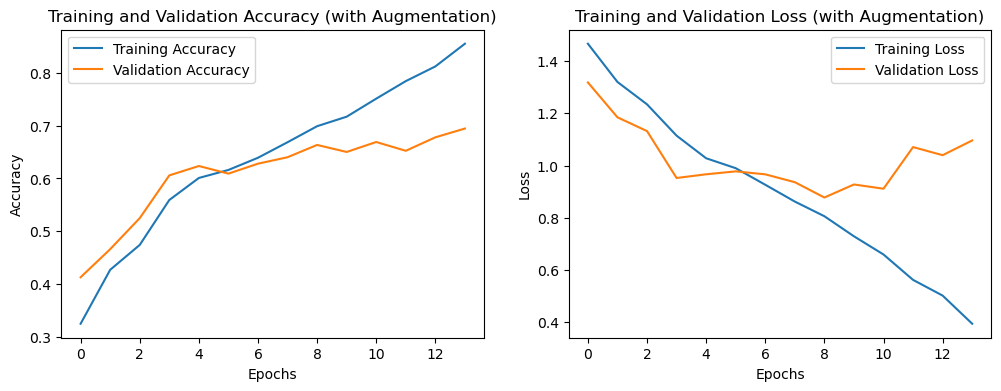

In [45]:
# Plot learning curves
plt.figure(figsize=(12, 4))

# Plot Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy (with Augmentation)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss (with Augmentation)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [46]:
# Evaluate model on test data
y_true, y_pred = [], []

for images, labels in test_data:
    predictions = model.predict(images, verbose=0)
    y_pred.extend(np.argmax(predictions, axis=1))
    y_true.extend(np.argmax(labels.numpy(), axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)


In [47]:
# Calculate performance metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average='weighted')
recall = recall_score(y_true, y_pred, average='weighted')
f1 = f1_score(y_true, y_pred, average='weighted')

print("\n--- Model Performance with Data Augmentation ---")
print("Accuracy: {:.2f}%".format(accuracy * 100))
print("Precision: {:.2f}".format(precision))
print("Recall: {:.2f}".format(recall))
print("F1 Score: {:.2f}".format(f1))


--- Model Performance with Data Augmentation ---
Accuracy: 67.47%
Precision: 0.69
Recall: 0.67
F1 Score: 0.67


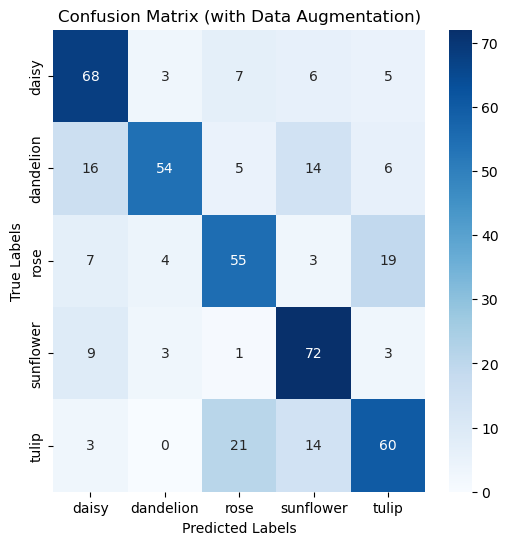

In [48]:
# Compute and plot the confusion matrix
cm = confusion_matrix(y_true, y_pred)
class_names = ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']  # Update if your classes are different

plt.figure(figsize=(6, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.title("Confusion Matrix (with Data Augmentation)")
plt.show()

**In this iteration I actually got a worse result ≈ 67% than the previous CNN iteration ≈ 73%**

## 5. Transfer Learning with MobileNetV2 (Iteration 3)

### Preprocessing

##### Preprocessing Steps for Transfer Learning

1. **Define Constants:**
   - **IMAGE_SIZE = (180, 180):**  
     Every image will be resized to 180x180 pixels.
   - **BATCH_SIZE = 64:**  
     Images will be processed in batches of 64 during training.

2. **Load Data from Directories:**
   - **Training Data:**  
     Images are loaded from the training directory (`train_path`). They are resized, batched, and labeled using a categorical format. The data is shuffled to randomize the order.
   - **Validation Data:**  
     Similarly, images are loaded from the validation directory (`val_path`) with the same settings.
   - **Test Data:**  
     Images are loaded from the test directory (`test_path`) with similar processing.
   - The printed output indicates the number of images (files) found for each dataset.

3. **Apply MobileNetV2 Preprocessing:**
   - MobileNetV2 requires images to be normalized in a specific way.  
     The function `tf.keras.applications.mobilenet_v2.preprocess_input` is used to apply the necessary preprocessing to the images.
   - This preprocessing is applied to each dataset (training, validation, test) using the `map` function.

4. **Optimize Data Pipeline:**
   - **Caching:**  
     Using `.cache()` stores the dataset in memory after the first epoch, which speeds up data retrieval in subsequent epochs.
   - **Shuffling (for training data):**  
     The `shuffle(1000)` method randomizes the order of images to help improve model training.
   - **Prefetching:**  
     Using `.prefetch(buffer_size=AUTOTUNE)` allows the data pipeline to prepare the next batch of data while the current batch is being processed. This helps in maintaining a smooth training process.


In [49]:
# Define image size and batch size for our training configuration
IMAGE_SIZE = (180, 180)
BATCH_SIZE = 64  

In [50]:
# Load training data
train_data = tf.keras.preprocessing.image_dataset_from_directory(
    train_path,
    label_mode='categorical',
    batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE,
    shuffle=True
)

Found 3167 files belonging to 5 classes.


In [51]:
# Load validation data
val_data = tf.keras.preprocessing.image_dataset_from_directory(
    val_path,
    label_mode='categorical',
    batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE,
    shuffle=True
)

Found 903 files belonging to 5 classes.


In [52]:
# Load test data
test_data = tf.keras.preprocessing.image_dataset_from_directory(
    test_path,
    label_mode='categorical',
    batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE,
    shuffle=True
)

Found 458 files belonging to 5 classes.


In [53]:
# Apply MobileNetV2 preprocessing
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input

# Preprocess the datasets
train_data = train_data.map(lambda x, y: (preprocess_input(x), y))
val_data = val_data.map(lambda x, y: (preprocess_input(x), y))
test_data = test_data.map(lambda x, y: (preprocess_input(x), y))

In [54]:
# Optimize performance with caching and prefetching
AUTOTUNE = tf.data.AUTOTUNE
train_data = train_data.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_data = val_data.cache().prefetch(buffer_size=AUTOTUNE)
test_data = test_data.prefetch(buffer_size=AUTOTUNE)

### CNN Architecture

##### CNN Architecture Strategy Using Transfer Learning

1. **Base Model (MobileNetV2):**
   - **Pre-trained Weights:**  
     MobileNetV2 is initialized with weights pre-trained on ImageNet, providing robust feature extraction learned from a large dataset.
   - **Removing the Top Layer:**  
     Setting `include_top=False` removes the original classification head, allowing us to customize the network for our specific 5-class problem.
   - **Freezing the Base Model:**  
     By setting `base_model.trainable = False`, we prevent the pre-trained weights from updating during training. This helps retain the useful features learned on ImageNet and speeds up training.

2. **Custom Classification Layers:**
   - **GlobalAveragePooling2D:**  
     This layer converts the feature maps from the base model into a single vector per image by computing the average of each feature map, reducing the spatial dimensions.
   - **Dense Layer (256 neurons with ReLU):**  
     A fully connected layer that learns to combine the features extracted by the base model into higher-level representations.
   - **Dropout (0.5):**  
     A dropout layer randomly disables 50% of the neurons during training to help prevent overfitting.
   - **Final Dense Layer (5 neurons with Softmax):**  
     The final classification layer outputs probabilities for each of the 5 classes using the softmax activation function.

3. **Compilation:**
   - **Optimizer and Learning Rate:**  
     The model is compiled using the Adam optimizer with a learning rate of 0.0001, which is well-suited for fine-tuning.
   - **Loss Function:**  
     Categorical cross-entropy is used because the task involves multi-class classification.
   - **Metrics:**  
     Accuracy is monitored to evaluate model performance.

In [55]:
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(*IMAGE_SIZE, 3))
base_model.trainable = False

In [56]:
model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(256, activation='relu'), 
    Dropout(0.5), 
    Dense(5, activation='softmax') 
])

# Compile the model with Adam optimizer and categorical cross-entropy loss
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

Model: "sequential_6"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 mobilenetv2_1.00_224 (Func  (None, 6, 6, 1280)        2257984   
 tional)                                                         
                                                                 
 global_average_pooling2d (  (None, 1280)              0         
 GlobalAveragePooling2D)                                         
                                                                 
 dense_13 (Dense)            (None, 256)               327936    
                                                                 
 dropout_2 (Dropout)         (None, 256)               0         
                                                                 
 dense_14 (Dense)            (None, 5)                 1285      
                                                                 
Total params: 2587205 (9.87 MB)
Trainable params: 3292

### CNN Training

##### CNN Training Strategy

1. **Early Stopping Callback:**  
   - An early stopping mechanism is set up to monitor the validation loss (`val_loss`).  
   - If the validation loss does not improve for 5 consecutive epochs (patience=5), training stops automatically.  
   - The callback also restores the best weights from the epoch with the lowest validation loss to prevent overfitting.

2. **Model Training Process:**  
   - The model is trained using the `fit()` function, where both training (`train_data`) and validation data (`val_data`) are provided.  
   - Although the model is set to run for up to 70 epochs, training may stop earlier due to the early stopping mechanism if no further improvements are observed.
   - During each epoch, the model prints training and validation loss as well as accuracy, which helps in monitoring performance over time.

3. **Overall Strategy:**  
   - This approach helps prevent overfitting by stopping the training once the model's performance on unseen data (validation set) no longer improves.
   - It also saves training time and computational resources by avoiding unnecessary epochs.



In [57]:
# Setup early stopping to avoid overfitting
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

# Train the model with fewer epochs because it takes longer to train
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=70,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/70
50/50 [==============================] - 20s 311ms/step - loss: 1.5623 - accuracy: 0.4080 - val_loss: 0.8459 - val_accuracy: 0.7043
Epoch 2/70
50/50 [==============================] - 13s 259ms/step - loss: 0.8813 - accuracy: 0.6707 - val_loss: 0.6165 - val_accuracy: 0.7996
Epoch 3/70
50/50 [==============================] - 13s 258ms/step - loss: 0.6877 - accuracy: 0.7502 - val_loss: 0.5201 - val_accuracy: 0.8317
Epoch 4/70
50/50 [==============================] - 13s 260ms/step - loss: 0.6044 - accuracy: 0.7828 - val_loss: 0.4743 - val_accuracy: 0.8383
Epoch 5/70
50/50 [==============================] - 15s 295ms/step - loss: 0.5258 - accuracy: 0.8087 - val_loss: 0.4371 - val_accuracy: 0.8527
Epoch 6/70
50/50 [==============================] - 14s 287ms/step - loss: 0.4911 - accuracy: 0.8285 - val_loss: 0.4113 - val_accuracy: 0.8660
Epoch 7/70
50/50 [==============================] - 14s 292ms/step - loss: 0.4484 - accuracy: 0.8446 - val_loss: 0.3934 - val_accuracy: 0.8638

### Model Evaluation

##### Model Evaluation Strategy

1. **Learning Curve Visualization:**  
   - We plot the training and validation accuracy and loss curves over epochs.  
   - These plots help us monitor the model’s learning progress and diagnose issues like overfitting or underfitting.

2. **Test Data Predictions:**  
   - The trained model makes predictions on the test dataset.  
   - We collect both the true labels and the predicted labels to assess how well the model performs on unseen data.

3. **Performance Metrics Calculation:**  
   - We calculate key metrics such as accuracy, precision, recall, and F1 score.  
   - These metrics provide a comprehensive view of the model’s classification performance across all classes.

4. **Confusion Matrix:**  
   - A confusion matrix is computed and visualized using a heatmap.  
   - This matrix shows the correct and incorrect predictions for each class, allowing us to identify specific areas of strength and weakness.


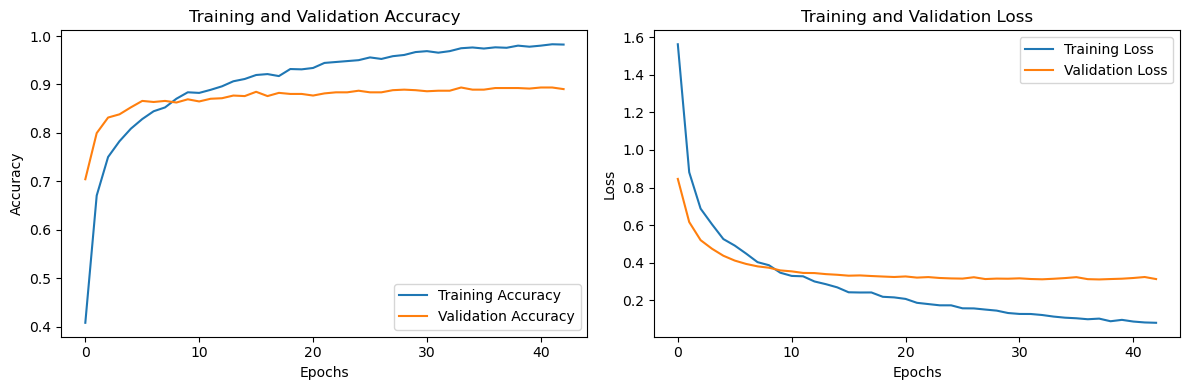

In [58]:
# Plot training and validation learning curves
plt.figure(figsize=(12, 4))

# Plot Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

In [59]:
# Collect predictions and true labels from test_data
y_true = []
y_pred = []

for images, labels in test_data:
    predictions = model.predict(images)
    y_pred.extend(np.argmax(predictions, axis=1))
    y_true.extend(np.argmax(labels.numpy(), axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

1/1 [==============================] - 1s 1s/step


In [60]:
# Calculate performance metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average='weighted')
recall = recall_score(y_true, y_pred, average='weighted')
f1 = f1_score(y_true, y_pred, average='weighted')

print("Test Metrics:")
print("Accuracy: {:.2f}%".format(accuracy * 100))
print("Precision: {:.2f}".format(precision))
print("Recall: {:.2f}".format(recall))
print("F1 Score: {:.2f}".format(f1))

Test Metrics:
Accuracy: 89.52%
Precision: 0.90
Recall: 0.90
F1 Score: 0.90


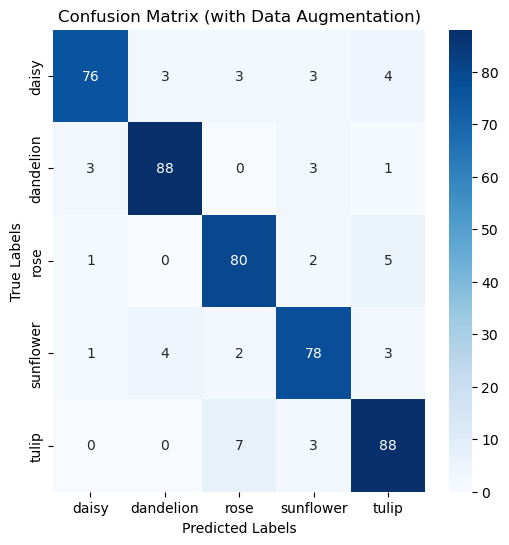

In [61]:
# Compute and plot the confusion matrix
cm = confusion_matrix(y_true, y_pred)
class_names = ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']  # Update if your classes are different

plt.figure(figsize=(6, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.title("Confusion Matrix (with Data Augmentation)")
plt.show()

**In this iteration I got a much better result than the previous 2 iterations with accuracy of ≈ 89%**

## 6. Model Improvement with EfficientNetB0 (Iteration 4)

### Preprocessing

##### Preprocessing Steps for Model Improvement (Iteration 4)

1. **Image Size & Batch Configuration:**  
   - **IMAGE_SIZE = (220, 220):**  
     Images are resized to 220x220 pixels to match the input requirements for EfficientNetB0.
   - **BATCH_SIZE = 64:**  
     Images are processed in batches of 64, which is used consistently for training, validation, and testing.

2. **Data Loading:**  
   - **Training Data:**  
     Images are loaded from the training directory with categorical labels. The dataset reports 3167 files across 5 classes, and images are shuffled during loading.
   - **Validation Data:**  
     Similarly, images are loaded from the validation directory (903 files, 5 classes).
   - **Test Data:**  
     Test images are loaded from the test directory (458 files, 5 classes).

3. **EfficientNetB0 Preprocessing:**  
   - The function `tf.keras.applications.efficientnet.preprocess_input` is applied to all datasets.  
     This preprocessing normalizes the images according to the specifications required by EfficientNetB0, ensuring optimal input for the model.

4. **Data Pipeline Optimization:**  
   - **Caching:**  
     Caching the datasets improves performance by storing the processed data in memory.
   - **Shuffling:**  
     The training data is shuffled with a buffer size of 1000 to help in randomizing the order of the data.
   - **Prefetching:**  
     Prefetching with `AUTOTUNE` allows the data to be prepared in parallel with model training, thus reducing bottlenecks.


In [62]:
# Define image size and batch size for our training configuration
IMAGE_SIZE = (220, 220)
BATCH_SIZE = 64  

In [63]:
# Load training data
train_data = tf.keras.preprocessing.image_dataset_from_directory(
    train_path,
    label_mode='categorical',
    batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE,
    shuffle=True
)

Found 3167 files belonging to 5 classes.


In [64]:
# Load validation data
val_data = tf.keras.preprocessing.image_dataset_from_directory(
    val_path,
    label_mode='categorical',
    batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE,
    shuffle=True
)

Found 903 files belonging to 5 classes.


In [65]:
# Load test data
test_data = tf.keras.preprocessing.image_dataset_from_directory(
    test_path,
    label_mode='categorical',
    batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE,
    shuffle=True
)

Found 458 files belonging to 5 classes.


In [66]:
# Apply EfficientNetB0 preprocessing
preprocess_input = tf.keras.applications.efficientnet.preprocess_input

# Preprocess the datasets
train_data = train_data.map(lambda x, y: (preprocess_input(x), y))
val_data = val_data.map(lambda x, y: (preprocess_input(x), y))
test_data = test_data.map(lambda x, y: (preprocess_input(x), y))

In [67]:
# Optimize performance with caching and prefetching
AUTOTUNE = tf.data.AUTOTUNE
train_data = train_data.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_data = val_data.cache().prefetch(buffer_size=AUTOTUNE)
test_data = test_data.prefetch(buffer_size=AUTOTUNE)

### CNN Architecture

##### CNN Architecture Strategy for Model Improvement (Iteration 4)

1. **EfficientNetB0 as the Base Model:**  
   - **Pre-trained on ImageNet:**  
     EfficientNetB0 is loaded with pre-trained weights, allowing it to leverage learned features from a large dataset.
   - **Excluding the Top Layer:**  
     By setting `include_top=False`, we remove the original classification head to add our own custom layers.
   - **Freezing the Base Model:**  
     The base model's weights are frozen (`base_model.trainable = False`) to retain its learned representations and reduce training complexity.

2. **Feature Pooling:**  
   - **Global Average Pooling:**  
     A `GlobalAveragePooling2D` layer converts the multi-dimensional feature maps from the base model into a single vector per image. This reduces the number of parameters and helps prevent overfitting.

3. **Custom Classifier Layers:**  
   - **Dense Layer with 256 Neurons:**  
     The first dense layer with ReLU activation learns high-level features from the pooled output.
   - **Batch Normalization:**  
     Normalizes activations from the dense layer to improve training stability and speed up convergence.
   - **Dropout (0.5):**  
     A dropout layer with a rate of 50% is used to reduce overfitting by randomly disabling neurons during training.
   - **Second Dense Layer with 128 Neurons:**  
     Adds another level of feature abstraction and further refines the learned representations.
   - **Additional Batch Normalization and Dropout (0.3):**  
     Further stabilizes and regularizes the model with another batch normalization layer and a dropout layer (30% rate).
   - **Output Layer:**  
     A final dense layer with 5 neurons and softmax activation provides probability distributions for the 5 classes.

4. **Model Compilation:**  
   - **Optimizer:**  
     Compiled with the Adam optimizer using a learning rate of 0.001.
   - **Loss Function:**  
     Categorical cross-entropy is used since the task involves multi-class classification.
   - **Metrics:**  
     Accuracy is monitored to evaluate model performance during training.

In [68]:
# Load EfficientNetB0 base model
base_model = tf.keras.applications.EfficientNetB0(
    weights='imagenet',
    include_top=False,
    input_shape=(*IMAGE_SIZE, 3)
)
base_model.trainable = False

In [69]:
# Build the model with data augmentation and batch normalization
model = tf.keras.Sequential([

    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(5, activation='softmax')
])

# Compile the initial model with Adam optimizer and categorical cross-entropy loss
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.build((None, *IMAGE_SIZE, 3))
model.summary()

Model: "sequential_7"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 efficientnetb0 (Functional  (None, 7, 7, 1280)        4049571   
 )                                                               
                                                                 
 global_average_pooling2d_1  (None, 1280)              0         
  (GlobalAveragePooling2D)                                       
                                                                 
 dense_15 (Dense)            (None, 256)               327936    
                                                                 
 batch_normalization (Batch  (None, 256)               1024      
 Normalization)                                                  
                                                                 
 dropout_3 (Dropout)         (None, 256)               0         
                                                      

### CNN Training

##### CNN Training Strategy for Model Improvement (Iteration 4)

1. **Callback Setup:**
   - **Early Stopping:**  
     An early stopping callback monitors the validation loss (`val_loss`) and stops training if it does not improve for 5 consecutive epochs. This ensures that the model doesn't overfit and training time is saved by reverting to the best model weights.
   - **Learning Rate Scheduler:**  
     A ReduceLROnPlateau callback is configured to halve the learning rate if no improvement in `val_loss` is observed for 3 epochs. This helps the model fine-tune during later stages of training by allowing smaller updates.

2. **Training Process:**
   - **Epochs and Data:**  
     The model is set to train for a maximum of 50 epochs on the preprocessed training dataset while using the validation dataset to monitor performance.
   - **Real-time Feedback:**  
     Training logs provide real-time updates on loss, accuracy, and learning rate, which helps in monitoring the learning progress and adjusting strategies if needed.

3. **Overall Strategy:**
   - The combination of early stopping and adaptive learning rate scheduling ensures efficient training by preventing overfitting and dynamically adjusting the learning rate as the model converges.


In [70]:
# Setup callbacks for early stopping and learning rate scheduling
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)


history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=50,
    callbacks=[early_stop, lr_scheduler],
    verbose=1
)


Epoch 1/50
50/50 [==============================] - 41s 647ms/step - loss: 0.7786 - accuracy: 0.7322 - val_loss: 0.4261 - val_accuracy: 0.9025 - lr: 0.0010
Epoch 2/50
50/50 [==============================] - 29s 576ms/step - loss: 0.3801 - accuracy: 0.8721 - val_loss: 0.2905 - val_accuracy: 0.9247 - lr: 0.0010
Epoch 3/50
50/50 [==============================] - 28s 572ms/step - loss: 0.2881 - accuracy: 0.9024 - val_loss: 0.2500 - val_accuracy: 0.9269 - lr: 0.0010
Epoch 4/50
50/50 [==============================] - 33s 660ms/step - loss: 0.2217 - accuracy: 0.9220 - val_loss: 0.2263 - val_accuracy: 0.9247 - lr: 0.0010
Epoch 5/50
50/50 [==============================] - 32s 646ms/step - loss: 0.1791 - accuracy: 0.9378 - val_loss: 0.2029 - val_accuracy: 0.9336 - lr: 0.0010
Epoch 6/50
50/50 [==============================] - 33s 663ms/step - loss: 0.1574 - accuracy: 0.9451 - val_loss: 0.2082 - val_accuracy: 0.9347 - lr: 0.0010
Epoch 7/50
50/50 [==============================] - 32s 651ms/st

### Model Evaluation

##### Model Evaluation Strategy for Model Improvement (Iteration 4)

1. **Learning Curve Visualization:**  
   - **Accuracy and Loss Plots:**  
     We plot training and validation accuracy and loss curves over epochs to visualize how well the model is learning. These plots help in identifying issues like overfitting or underfitting by comparing the training and validation performance over time.

2. **Test Data Predictions:**  
   - **Collecting Predictions and True Labels:**  
     After training, we run the model on the test dataset to gather predicted labels alongside the true labels. This step ensures that our evaluation reflects the model's performance on unseen data.

3. **Performance Metrics Calculation:**  
   - **Key Metrics:**  
     We calculate accuracy, precision, recall, and F1 score using the test predictions. These metrics provide a detailed understanding of the model’s performance, especially in a multi-class classification context.

4. **Confusion Matrix Analysis:**  
   - **Visualizing Misclassifications:**  
     The confusion matrix is computed and visualized using a heatmap. It shows the number of correct and incorrect predictions for each class, allowing us to pinpoint specific areas where the model might be confusing one class for another.


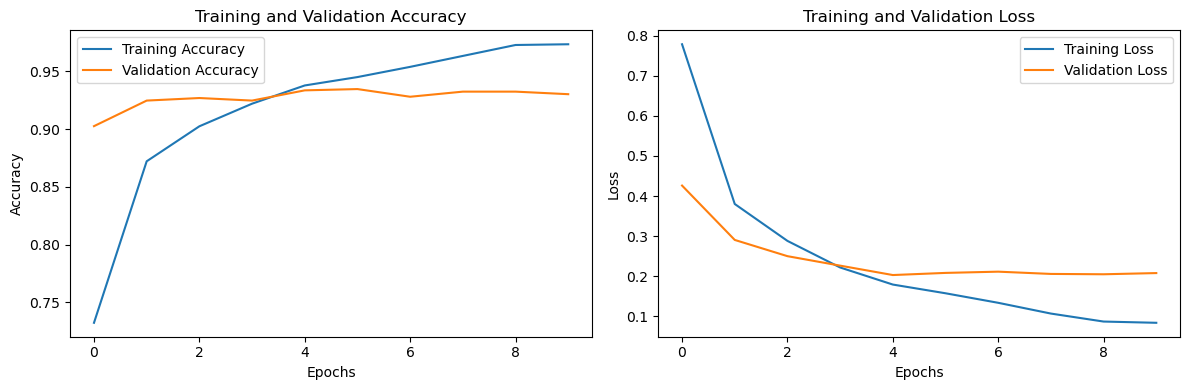

In [71]:
# Plot training and validation learning curves
plt.figure(figsize=(12, 4))

# Plot Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

In [72]:
# Collect predictions and true labels from test_data
y_true = []
y_pred = []

for images, labels in test_data:
    predictions = model.predict(images)
    y_pred.extend(np.argmax(predictions, axis=1))
    y_true.extend(np.argmax(labels.numpy(), axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

1/1 [==============================] - 2s 2s/step


In [73]:
# Calculate performance metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average='weighted')
recall = recall_score(y_true, y_pred, average='weighted')
f1 = f1_score(y_true, y_pred, average='weighted')

print("Test Metrics:")
print("Accuracy: {:.2f}%".format(accuracy * 100))
print("Precision: {:.2f}".format(precision))
print("Recall: {:.2f}".format(recall))
print("F1 Score: {:.2f}".format(f1))

Test Metrics:
Accuracy: 95.41%
Precision: 0.96
Recall: 0.95
F1 Score: 0.95


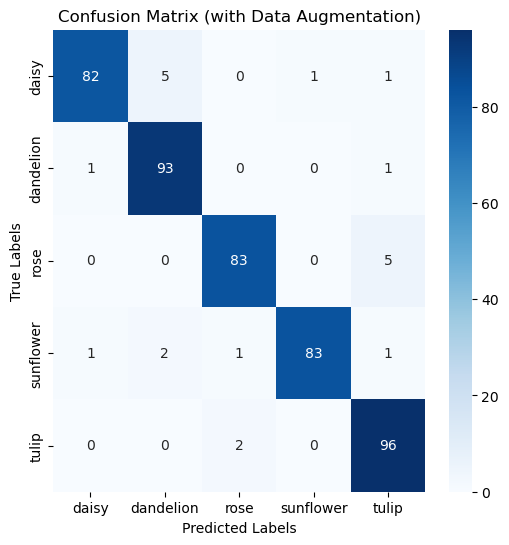

In [74]:
# Compute and plot the confusion matrix
cm = confusion_matrix(y_true, y_pred)
class_names = ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']

plt.figure(figsize=(6, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.title("Confusion Matrix (with Data Augmentation)")
plt.show()

**In my last iteration I got the best accuracy yet with ≈ 95%**

## 7. Error Analysis

### Wrong Classifications

In [75]:
y_true = []
y_pred = []
images_list = []

for images, labels in test_data:
    preds = model.predict(images)
    y_true_batch = np.argmax(labels.numpy(), axis=1)
    y_pred_batch = np.argmax(preds, axis=1)

    y_true.extend(y_true_batch)
    y_pred.extend(y_pred_batch)
    images_list.extend(images.numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred)
images_list = np.array(images_list)


1/1 [==============================] - 0s 157ms/step


In [76]:
misclassified_indices = np.where(y_true != y_pred)[0]
print(f"Number of misclassified samples: {len(misclassified_indices)}")


Number of misclassified samples: 21


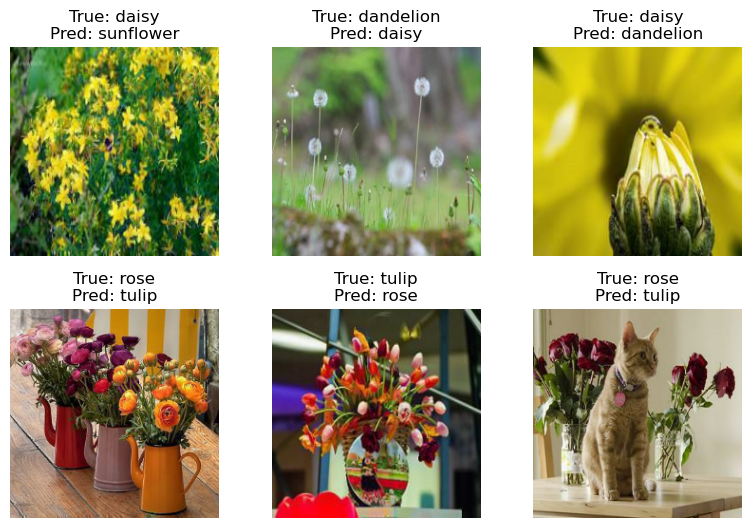

In [77]:
num_images = min(6, len(misclassified_indices))
if num_images == 0:
    print("No misclassified images found.")
else:
    plt.figure(figsize=(8, 8))
    for i in range(num_images):
        idx = misclassified_indices[i]
        plt.subplot(3, 3, i + 1)
        plt.imshow(images_list[idx].astype("uint8"))
        plt.title(f"True: {class_names[y_true[idx]]}\nPred: {class_names[y_pred[idx]]}")
        plt.axis("off")
    plt.tight_layout()
    plt.show()


In [78]:
from collections import Counter
misclassified_counts = Counter([class_names[y_true[i]] for i in range(len(y_true)) if y_true[i] != y_pred[i]])
print(misclassified_counts)

Counter({'daisy': 7, 'rose': 5, 'sunflower': 5, 'dandelion': 2, 'tulip': 2})


In [79]:
# Images where prediction was often wrong
for idx, (true, pred) in enumerate(zip(y_true, y_pred)):
    if true != pred and class_names[true] == "rose":
        print(f"Index: {idx} | True: {class_names[true]} | Pred: {class_names[pred]}")


Index: 33 | True: rose | Pred: tulip
Index: 103 | True: rose | Pred: tulip
Index: 116 | True: rose | Pred: tulip
Index: 291 | True: rose | Pred: tulip
Index: 360 | True: rose | Pred: tulip


### Identify Error Types

After looking at the misclassified images and the model’s predictions, here are some possible reasons for the mistakes:

1. **Similar-Looking Flowers**  
   Some flowers, like **daisies, dandelions, and sunflowers**, look very similar. They often have yellow petals and similar shapes, which can confuse the model.

2. **Confusing Roses**  
   The model had a hard time with **roses**. It often confused them with **tulips** or **sunflowers**. This might be because some rose images were blurry or didn’t clearly show rose features.

3. **Distracting Backgrounds**  
   Some images had busy backgrounds or reflections that made it hard for the model to focus on the flower. For example, one sunflower was shown inside a glass ball and was wrongly predicted as a dandelion.

4. **Zoomed-In or Cropped Images**  
   Some pictures showed only part of the flower. This made it difficult for the model to understand what type of flower it was, especially with sunflowers and dandelions.

5. **Bad Lighting or Blurry Images**  
   A few images were dark or out of focus, which made it harder for the model to see the flower’s colors and shapes.


### Categorize Errors

We grouped the 29 misclassified images from an earlier training run of this model into different error types (the final run shown above has 21 misclassified test images). Here's how many images fall under each group and what percentage they represent:

| Error Type                          | Count | Percentage |
|-------------------------------------|-------|------------|
| 1. Similar-Looking Flowers          | 12    | 41.4%      |
| 2. Misclassified Roses              | 9     | 31.0%      |
| 3. Distracting Backgrounds          | 3     | 10.3%      |
| 4. Cropped or Zoomed-In Flowers     | 3     | 10.3%      |
| 5. Bad Lighting / Blurry Images     | 2     | 6.9%       |
| **Total**                           | **29**| **100%**   |

#### Explanation

- **Similar-Looking Flowers (41.4%)**: Most mistakes happened between daisy, dandelion, and sunflower. These flowers have similar colors and shapes.
- **Misclassified Roses (31.0%)**: The model confused roses mainly with tulips and sunflowers.
- **Distracting Backgrounds (10.3%)**: Some images had objects or reflections that confused the model.
- **Cropped/Zoomed-In Flowers (10.3%)**: When only part of the flower was shown, the model struggled to identify it.
- **Blurry or Dark Images (6.9%)**: Low quality images affected the model’s ability to detect features.

### Propose Improvements

##### Hypotheses for Errors

Based on the quantitative analysis, we can make the following guesses (hypotheses) about why these errors happened:

1. **Similar-Looking Flowers**  
   Hypothesis: The model struggles to tell apart flowers with similar shapes and colors, like daisy, dandelion, and sunflower, because they look too alike in many images.

2. **Misclassified Roses**  
   Hypothesis: The model hasn’t seen enough varied examples of roses during training. It may also not recognize rose features when the image is blurry, dark, or taken from a different angle.

3. **Distracting Backgrounds**  
   Hypothesis: The model sometimes focuses on the background instead of the flower, especially when there are reflections or other objects in the image.

4. **Cropped/Zoomed-In Flowers**  
   Hypothesis: The model finds it hard to identify flowers when only part of the flower is visible, because important visual clues are missing.

5. **Bad Lighting / Blurry Images**  
   Hypothesis: When images are dark or blurry, the model can't see clear features like color and petal shape, leading to wrong predictions.



##### Suggestions for Improvement

To help the model make better predictions, here are some improvements:

1. **Add More Training Images**
   - Include more examples of roses and other underrepresented classes.
   - Make sure the images show different lighting, angles, zoom levels, and backgrounds.

2. **Use Data Augmentation**
   - Randomly change brightness, contrast, zoom, and rotation during training.
   - This helps the model learn to handle real-world variations.

3. **Improve Label Quality**
   - Double-check that the training data is correctly labeled.
   - Mislabelled images can confuse the model.

4. **Add Attention Mechanisms**
   - Use models that focus more on important parts of the image (like the flower itself) instead of the background.

5. **Crop and Center Flowers**
   - Preprocess the images so the flower is always centered and fills most of the image.
   - This makes it easier for the model to learn key features.

6. **Try a Stronger Model Architecture**
   - Consider using a deeper or pre-trained model like EfficientNet, ResNet, or fine-tuning a model from ImageNet.



#### Final Thoughts

The biggest problems came from confusing similar flowers and not enough variation in the training data. By improving data quality, using augmentation, and choosing better models, we can likely reduce these mistakes and improve accuracy.
